In [ ]:
import os
import pydicom
import matplotlib.pyplot as plt
from skimage.segmentation import slic
from skimage.util import img_as_float
import numpy as np

In [ ]:
# dicom_dir = r"C:\Users\Abhishek Saha\Downloads\Journal dataser-1\z4wc364g79-1\JUH_MR-CT_dataset\MR\image_MR"
import os
from pathlib import Path

# Set DICOM_DIR to the location of your MRI dataset.
# If not set, look for the dataset in the project's data folder.
dicom_dir = Path(
    os.environ.get("DICOM_DIR", "data/MR/image_MR")
)

if not dicom_dir.is_dir():
    raise FileNotFoundError(
        f"MRI dataset directory not found: {dicom_dir}\n"
        "Set the DICOM_DIR environment variable to your dataset location."
    )

print(f"Using MRI dataset: {dicom_dir.resolve()}")


In [3]:
def load_dicom_images(directory):
    images = []
    filenames = []
    for file in os.listdir(directory):
        if file.endswith(".dcm"):
            filepath = os.path.join(directory, file)
            dicom = pydicom.dcmread(filepath)
            images.append(dicom.pixel_array)
            filenames.append(file)
    return images, filenames

In [4]:
def process_images_with_slic(images, n_segments=100, compactness=10):
    nodes_list = []
    segments_list = []
    for idx, image in enumerate(images):
        normalized_image = img_as_float(image)
        segments = slic(normalized_image, n_segments=n_segments, compactness=compactness, start_label=1)
        segments_list.append(segments)
        nodes = extract_node_features(image, segments)
        nodes_list.append(nodes)
    return nodes_list, segments_list

In [5]:
def extract_node_features(image, segments):
    nodes = {}
    for segment_id in np.unique(segments):
        mask = segments == segment_id
        mean_intensity = np.mean(image[mask])
        centroid = np.mean(np.argwhere(mask), axis=0)
        nodes[segment_id] = {'mean_intensity': mean_intensity, 'centroid': centroid}
    return nodes

In [6]:
def visualize_images(images, segments_list, filenames):
    for i, (image, segments, filename) in enumerate(zip(images, segments_list, filenames)):
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        axes[0].imshow(image, cmap='gray')
        axes[0].set_title(f"Original: {filename}")
        axes[1].imshow(segments, cmap='nipy_spectral')
        axes[1].set_title(f"SLIC Superpixels: {filename}")
        for ax in axes:
            ax.axis('off')
        plt.tight_layout()
        plt.show()

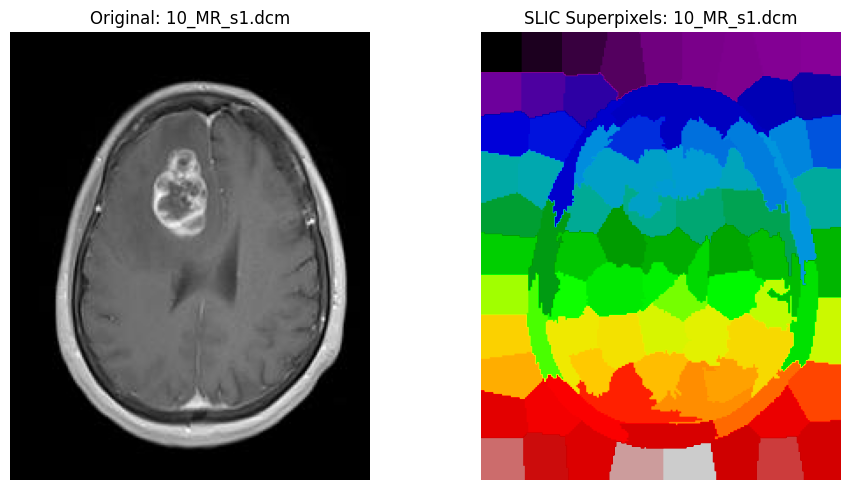

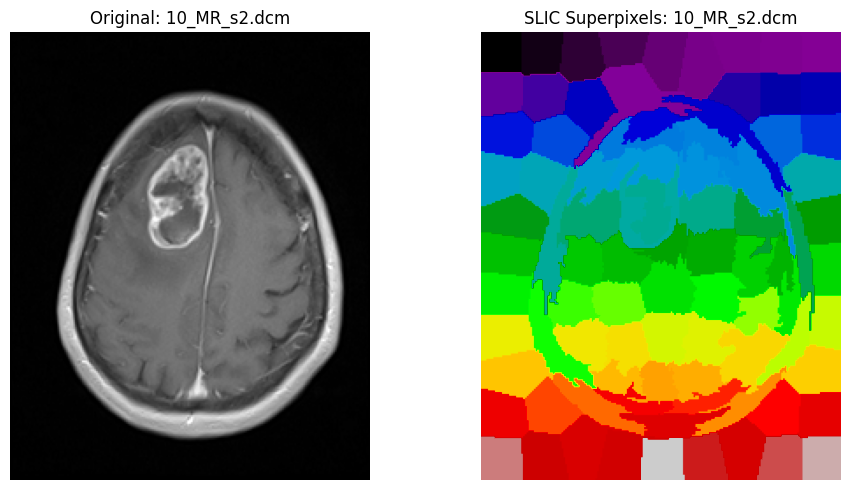

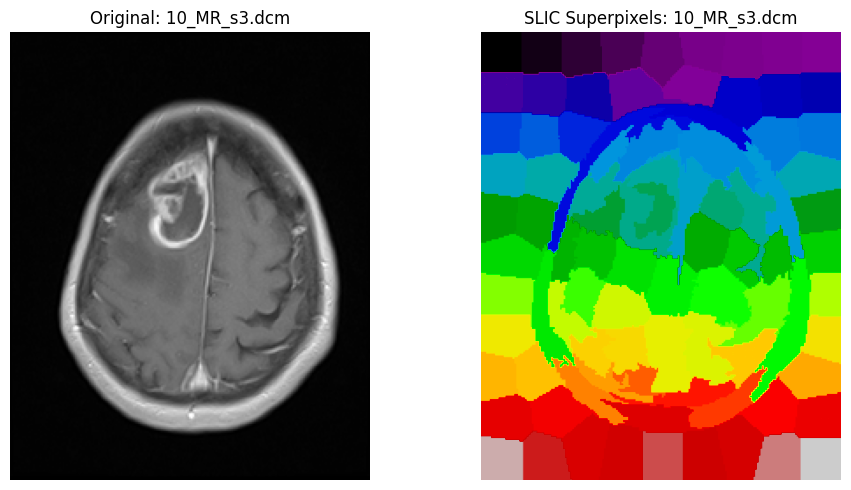

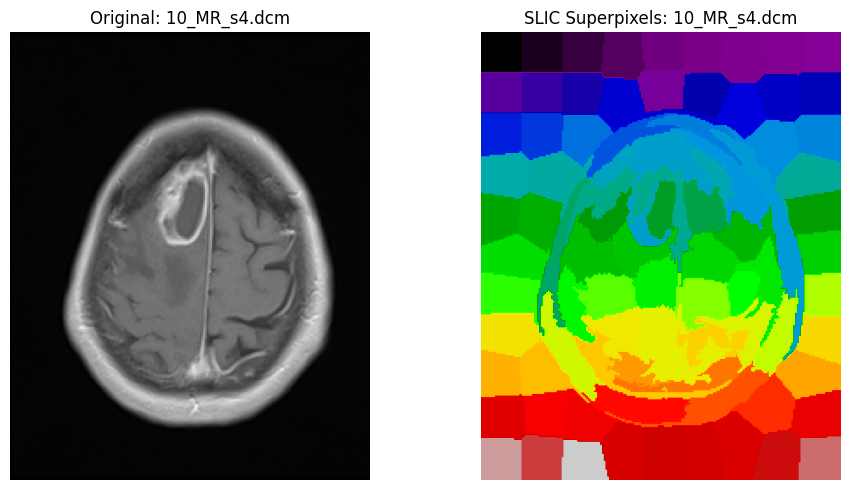

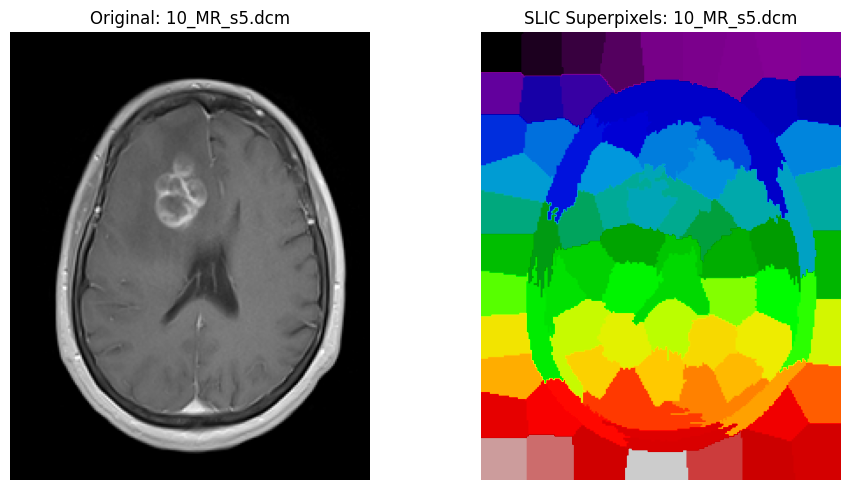

...

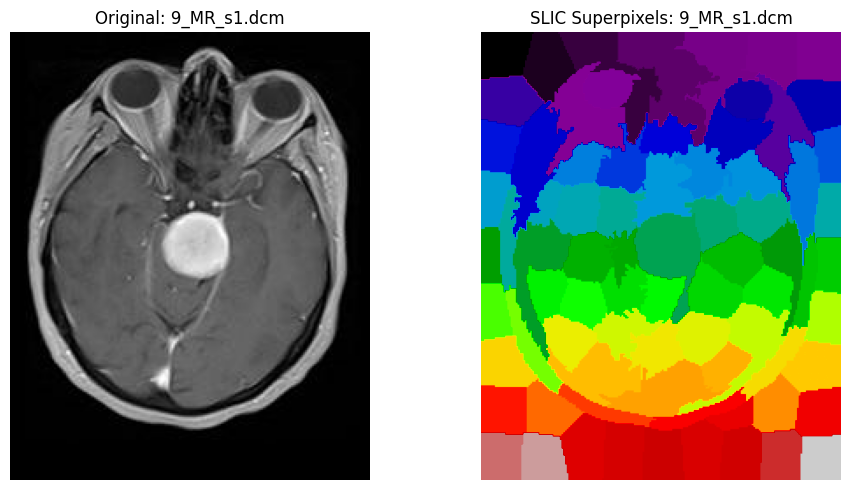

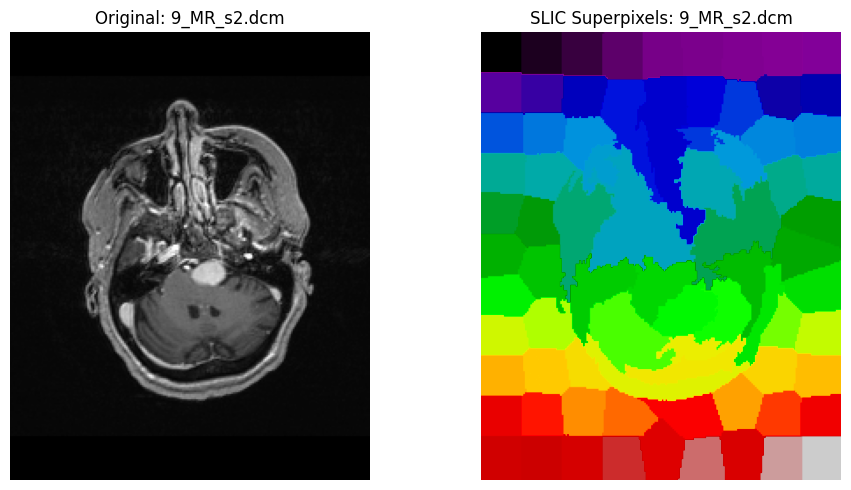

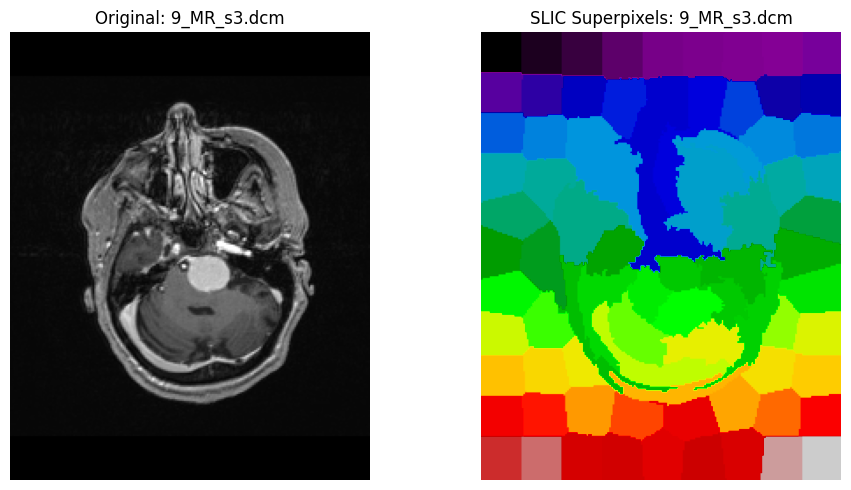

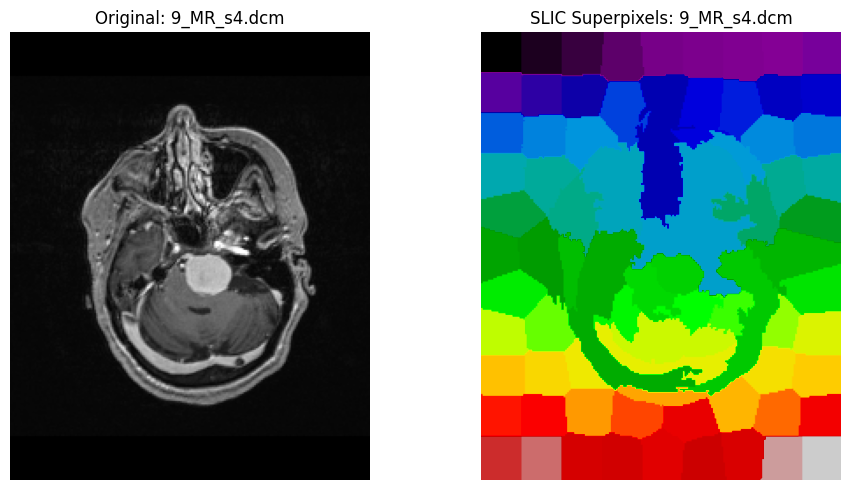

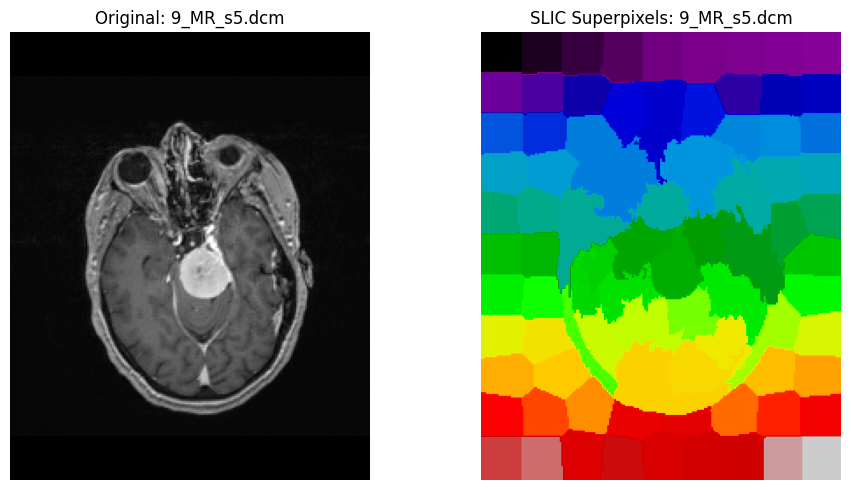

Node features for 10_MR_s1.dcm:
{1: {'mean_intensity': 0.0, 'centroid': array([11., 11.])}, 2: {'mean_intensity': 0.0, 'centroid': array([11., 34.])}, 3: {'mean_intensity': 0.0, 'centroid': array([11.21034483, 57.44655172])}, 4: {'mean_intensity': 4.001353179972936, 'centroid': array([16.87415426, 80.79296346])}, 5: {'mean_intensity': 3.5045045045045047, 'centroid': array([ 13.74474474, 102.95195195])}, 6: {'mean_intensity': 3.954876273653566, 'centroid': array([ 14.57933042, 125.49781659])}, 7: {'mean_intensity': 1.9633649932157395, 'centroid': array([ 18.16689281, 146.26322931])}, 8: {'mean_intensity': 0.0, 'centroid': array([ 11.9375    , 169.43589744])}, 9: {'mean_intensity': 0.0, 'centroid': array([ 11.49001815, 193.19419238])}, 10: {'mean_intensity': 0.0, 'centroid': array([34.21189591, 10.76765799])}, 11: {'mean_intensity': 0.0, 'centroid': array([34.41296928, 34.48464164])}, 12: {'mean_intensity': 4.410015649452269, 'centroid': array([36.36932707, 59.92488263])}, 13: {'mean_int

In [7]:
images, filenames = load_dicom_images(dicom_dir)
nodes_list, segments_list = process_images_with_slic(images)
visualize_images(images, segments_list, filenames)
print(f"Node features for {filenames[0]}:")
print(nodes_list[0])

In [8]:
from scipy.spatial.distance import cdist
import networkx as nx


In [9]:
def form_edges(nodes, segments):
    """
    Forms edges based on spatial adjacency and feature similarity.
    
    Parameters:
        nodes (dict): Node features for the superpixels.
        segments (ndarray): Superpixel labels for the image.
    
    Returns:
        adjacency_matrix (ndarray): Weighted adjacency matrix.
        graph (nx.Graph): NetworkX graph object for visualization or analysis.
        edge_index (torch.Tensor): Edge index for PyTorch Geometric.
    """
    num_nodes = len(nodes)
    adjacency_matrix = np.zeros((num_nodes, num_nodes))
    graph = nx.Graph()

    # Add nodes to the graph with their features
    for node_id, features in nodes.items():
        graph.add_node(node_id - 1, **features)  # Convert to zero-based indexing

    # Spatial adjacency: Check for neighboring superpixels
    for segment_id in np.unique(segments):
        neighbors = find_neighbors(segments, segment_id)
        for neighbor in neighbors:
            if (segment_id - 1 in graph.nodes) and (neighbor - 1 in graph.nodes):  # Ensure valid indices
                graph.add_edge(segment_id - 1, neighbor - 1)
                adjacency_matrix[segment_id - 1, neighbor - 1] = 1  # Binary adjacency

    # Feature similarity: Compute similarity between nodes
    centroids = np.array([nodes[n]['centroid'] for n in nodes])
    intensities = np.array([nodes[n]['mean_intensity'] for n in nodes]).reshape(-1, 1)

    intensity_similarity = cdist(intensities, intensities, metric='euclidean')
    for i in range(num_nodes):
        for j in range(i + 1, num_nodes):  # Avoid redundant calculations
            weight = np.exp(-intensity_similarity[i, j])  # Gaussian similarity
            graph.add_edge(i, j, weight=weight)  # Add weighted edge
            adjacency_matrix[i, j] = weight
            adjacency_matrix[j, i] = weight  # Symmetric matrix

    # Convert edges to PyTorch Geometric format
    edge_index = torch.tensor(list(graph.edges), dtype=torch.long).T

    return adjacency_matrix, graph, edge_index

In [10]:
def find_neighbors(segments, segment_id):
    """
    Finds neighboring superpixels for a given segment.
    
    Parameters:
        segments (ndarray): Superpixel segmentation map.
        segment_id (int): The ID of the superpixel for which neighbors are needed.

    Returns:
        set: A set of neighboring segment IDs.
    """
    mask = segments == segment_id  # Extract pixels belonging to the current superpixel
    neighbors = set()

    # Iterate through all pixels in the superpixel
    for i, j in np.argwhere(mask):
        for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]:  # 4-connectivity
            ni, nj = i + di, j + dj  # Neighboring pixel coordinates
            if 0 <= ni < segments.shape[0] and 0 <= nj < segments.shape[1]:  # Boundary check
                neighbor_id = segments[ni, nj]  # Get neighboring superpixel ID
                if neighbor_id != segment_id:  # Ensure different superpixel
                    neighbors.add(neighbor_id)

    return neighbors


C:\Users\Abhishek Saha\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\torch\utils\_pytree.py:185: FutureWarning: optree is installed but the version is too old to support PyTorch Dynamo in C++ pytree. C++ pytree support is disabled. Please consider upgrading optree using `python3 -m pip install --upgrade 'optree>=0.13.0'`.
  warnings.warn(


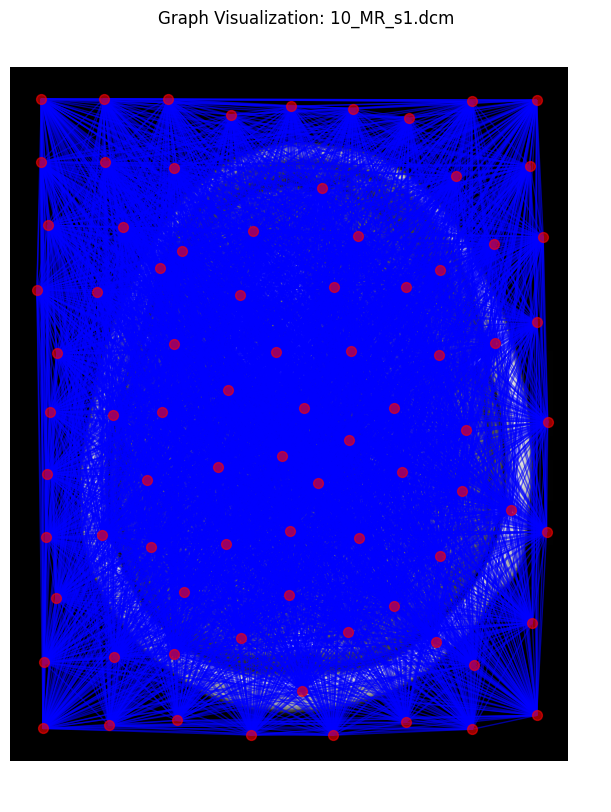

In [11]:

import networkx as nx
import matplotlib.pyplot as plt
import torch
def visualize_graph(image, segments, graph, filename):
    """
    Visualizes the graph structure overlaid on the MRI slice.
    
    Parameters:
        image (ndarray): The original MRI image.
        segments (ndarray): The superpixel labels.
        graph (nx.Graph): The constructed graph.
        filename (str): The name of the image file being visualized.
    """
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(image, cmap='gray')
    ax.set_title(f"Graph Visualization: {filename}")

    # Convert node features to a position dictionary for NetworkX
    pos = {}
    for node, features in graph.nodes(data=True):
        centroid = np.array(features['centroid'])  # Ensure centroid is an array
        pos[node] = (centroid[1], centroid[0])  # Convert to (x, y) format

    # Draw graph overlaid on MRI image
    nx.draw(graph, pos, ax=ax, node_size=50, node_color="red", edge_color="blue", alpha=0.6, with_labels=False)

    plt.show()

# Example usage on the first image
adj_matrix, graph, edge_index = form_edges(nodes_list[0], segments_list[0])
visualize_graph(images[0], segments_list[0], graph, filenames[0])


In [12]:
print(f"Number of nodes: {graph.number_of_nodes()}")
print(f"Number of edges: {graph.number_of_edges()}")


Number of nodes: 82
Number of edges: 3321


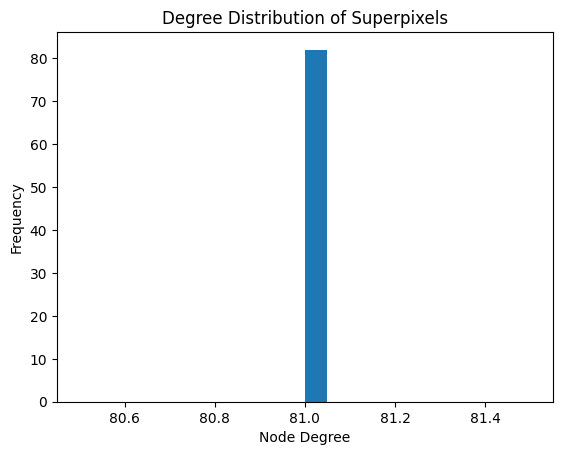

In [13]:
degrees = [graph.degree(n) for n in graph.nodes()]
plt.hist(degrees, bins=20)
plt.xlabel("Node Degree")
plt.ylabel("Frequency")
plt.title("Degree Distribution of Superpixels")
plt.show()


In [14]:
import torch
import numpy as np
from torch_geometric.data import Data

def convert_to_pyg_format(nodes, graph):
    """
    Converts graph data into PyTorch Geometric format.
    
    Parameters:
        nodes (dict): Dictionary of normalized node features.
        graph (nx.Graph): NetworkX graph representation.
    
    Returns:
        PyG data object
    """
    # Ensure node features are properly formatted
    x_features = []
    for n in nodes:
        mean_intensity = nodes[n]['mean_intensity']
        centroid = nodes[n]['centroid']  # This is a NumPy array (2,)

        # Convert centroid from NumPy array to a tuple of (x, y) scalars
        x_features.append([mean_intensity, centroid[0], centroid[1]])

    # Convert list to tensor
    x = torch.tensor(np.array(x_features), dtype=torch.float)

    # Extract edge connections (zero-based indexing)
    edge_index = torch.tensor(list(graph.edges), dtype=torch.long).T

    return Data(x=x, edge_index=edge_index)

# Convert the first graph in the dataset
pyg_data = convert_to_pyg_format(nodes_list[0], graph)
print(pyg_data)




Data(x=[82, 3], edge_index=[2, 3321])


In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
pyg_data.x = torch.tensor(scaler.fit_transform(pyg_data.x.cpu().numpy()), dtype=torch.float)


In [16]:
import torch.nn.functional as F
from torch_geometric.nn import GATConv, GINConv

class DualGraphEncoder(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels):
        super(DualGraphEncoder, self).__init__()
        
        # GAT Encoder for Spatial Graph
        self.gat1 = GATConv(in_channels, hidden_channels, heads=2, concat=False)
        self.gat2 = GATConv(hidden_channels, hidden_channels, heads=2, concat=False)
        
        # GIN Encoder for Feature Graph
        self.gin1 = GINConv(torch.nn.Linear(in_channels, hidden_channels))
        self.gin2 = GINConv(torch.nn.Linear(hidden_channels, hidden_channels))

    def forward(self, x, edge_index_spatial, edge_index_feature):
        # Encode using GAT (Spatial Graph)
        x_gat = self.gat1(x, edge_index_spatial)
        x_gat = F.relu(x_gat)
        x_gat = self.gat2(x_gat, edge_index_spatial)

        # Encode using GIN (Feature Graph)
        x_gin = self.gin1(x, edge_index_feature)
        x_gin = F.relu(x_gin)
        x_gin = self.gin2(x_gin, edge_index_feature)

        # Merge the embeddings (fusion layer)
        x_encoded = x_gat + x_gin  # Element-wise addition of learned features
        
        return x_encoded



In [17]:
class GraphDecoder(torch.nn.Module):
    def __init__(self, hidden_channels, out_channels):
        super(GraphDecoder, self).__init__()
        self.fc1 = torch.nn.Linear(hidden_channels, 128)
        self.fc2 = torch.nn.Linear(128, out_channels)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        return self.fc2(x)

In [18]:
class TumorGraphNetDGAE(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super(TumorGraphNetDGAE, self).__init__()
        self.encoder = DualGraphEncoder(in_channels, hidden_channels)
        self.decoder = GraphDecoder(hidden_channels, out_channels)

    def forward(self, x, edge_index_spatial, edge_index_feature):
        z = self.encoder(x, edge_index_spatial, edge_index_feature)
        reconstructed = self.decoder(z)
        return reconstructed


In [19]:
def train(model, data, optimizer, epochs=100):
    model.train()
    loss_fn = torch.nn.MSELoss()  # Reconstruction loss
    
    for epoch in range(epochs):
        optimizer.zero_grad()
        reconstructed = model(data.x, data.edge_index, data.edge_index)  # Using the same edge index for now
        loss = loss_fn(reconstructed, data.x)  # Minimize reconstruction error
        loss.backward()
        optimizer.step()

        if epoch % 10 == 0:
            print(f"Epoch {epoch}, Loss: {loss.item()}")

# Initialize model, optimizer, and train
in_channels = pyg_data.x.shape[1]  # Number of features per node
hidden_channels = 64
out_channels = 3  # Reconstruction target is same as input

model = TumorGraphNetDGAE(in_channels, hidden_channels, out_channels)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)

train(model, pyg_data, optimizer, epochs=300)



Epoch 0, Loss: 696.921142578125
Epoch 10, Loss: 53.41861343383789
Epoch 20, Loss: 34.441898345947266
Epoch 30, Loss: 2.96541690826416
Epoch 40, Loss: 3.084697961807251
Epoch 50, Loss: 2.1197762489318848
Epoch 60, Loss: 1.0667688846588135
Epoch 70, Loss: 0.9532697200775146
Epoch 80, Loss: 0.8573291897773743
Epoch 90, Loss: 0.7764092087745667
Epoch 100, Loss: 0.7557452917098999
Epoch 110, Loss: 0.7402010560035706
Epoch 120, Loss: 0.7271615862846375
Epoch 130, Loss: 0.712502121925354
Epoch 140, Loss: 0.6997273564338684
Epoch 150, Loss: 0.685115396976471
Epoch 160, Loss: 0.6693224310874939
Epoch 170, Loss: 0.6537675857543945
Epoch 180, Loss: 0.638951301574707
Epoch 190, Loss: 0.6241695880889893
Epoch 200, Loss: 0.6108761429786682
Epoch 210, Loss: 0.5972906947135925
Epoch 220, Loss: 0.5869041085243225
Epoch 230, Loss: 0.578140377998352
Epoch 240, Loss: 0.571174681186676
Epoch 250, Loss: 0.5652860403060913
Epoch 260, Loss: 0.5603178143501282
Epoch 270, Loss: 0.5525949597358704
Epoch 280, Los

In [20]:
def evaluate(model, data):
    model.eval()
    with torch.no_grad():
        reconstructed = model(data.x, data.edge_index, data.edge_index)
        loss = F.mse_loss(reconstructed, data.x)
        print(f"Reconstruction Loss: {loss.item()}")

evaluate(model, pyg_data)


Reconstruction Loss: 0.5434535145759583


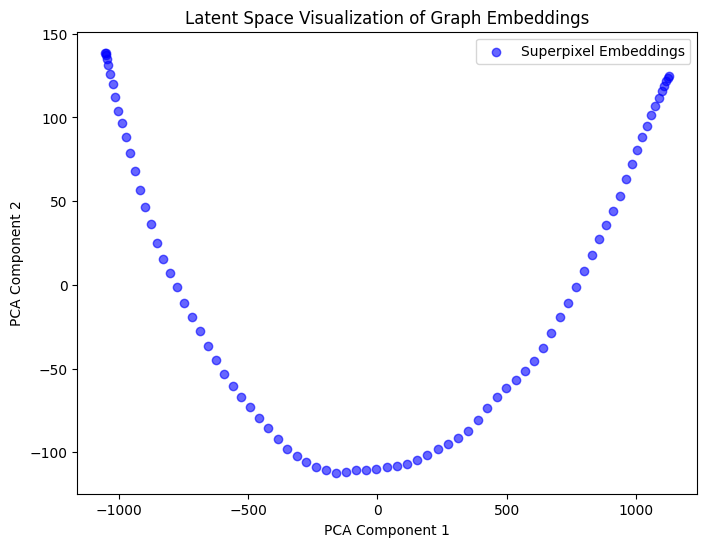

In [21]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

def visualize_latent_space(model, data):
    model.eval()
    with torch.no_grad():
        z = model.encoder(data.x, data.edge_index, data.edge_index)  # Extract embeddings

    # Reduce dimensionality for visualization (PCA to 2D)
    pca = PCA(n_components=2)
    z_2d = pca.fit_transform(z.cpu().numpy())

    plt.figure(figsize=(8, 6))
    plt.scatter(z_2d[:, 0], z_2d[:, 1], c="blue", alpha=0.6, label="Superpixel Embeddings")
    plt.xlabel("PCA Component 1")
    plt.ylabel("PCA Component 2")
    plt.title("Latent Space Visualization of Graph Embeddings")
    plt.legend()
    plt.show()

visualize_latent_space(model, pyg_data)


In [22]:
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0005, weight_decay=1e-5)


In [23]:
class GraphDecoder(torch.nn.Module):
    def __init__(self, hidden_channels, out_channels):
        super(GraphDecoder, self).__init__()
        self.fc1 = torch.nn.Linear(hidden_channels, 128)
        self.fc2 = torch.nn.Linear(128, 64)
        self.fc3 = torch.nn.Linear(64, out_channels)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)  # Final output layer


In [24]:
def train(model, data, optimizer, epochs=300):
    model.train()

    for epoch in range(epochs):
        optimizer.zero_grad()
        
        reconstructed = model(data.x, data.edge_index, data.edge_index)
        mse_loss = F.mse_loss(reconstructed, data.x)

        # Reduce weight of Graph Smoothness Loss (0.05 instead of 0.1)
        adjacency_matrix = torch.sparse_coo_tensor(
            data.edge_index, torch.ones(data.edge_index.shape[1], device=data.x.device),
            (data.x.shape[0], data.x.shape[0])
        )

        graph_loss = torch.norm(torch.sparse.mm(adjacency_matrix, reconstructed) - reconstructed)
        loss = mse_loss + 0.05 * graph_loss  # Lowered weight

        loss.backward()
        optimizer.step()

        if epoch % 10 == 0:
            print(f"Epoch {epoch}, Loss: {loss.item()}, MSE: {mse_loss.item()}, Graph Loss: {graph_loss.item()}")

# Train again with better features and improved decoder
train(model, pyg_data, optimizer, epochs=300)


Epoch 0, Loss: 13.118536949157715, MSE: 0.5434535145759583, Graph Loss: 251.5016632080078
Epoch 10, Loss: 245.55361938476562, MSE: 32.20099639892578, Graph Loss: 4267.05224609375
Epoch 20, Loss: 119.77118682861328, MSE: 9.824250221252441, Graph Loss: 2198.938720703125
Epoch 30, Loss: 131.75814819335938, MSE: 11.152280807495117, Graph Loss: 2412.117431640625
Epoch 40, Loss: 18.844463348388672, MSE: 0.9389288425445557, Graph Loss: 358.1106872558594
Epoch 50, Loss: 63.82242202758789, MSE: 2.309812307357788, Graph Loss: 1230.252197265625
Epoch 60, Loss: 48.6693000793457, MSE: 2.551879405975342, Graph Loss: 922.348388671875
Epoch 70, Loss: 21.64781379699707, MSE: 1.273734211921692, Graph Loss: 407.4815673828125
Epoch 80, Loss: 49.67720031738281, MSE: 1.6615222692489624, Graph Loss: 960.3135375976562
Epoch 90, Loss: 61.067779541015625, MSE: 2.7233715057373047, Graph Loss: 1166.88818359375
Epoch 100, Loss: 29.991302490234375, MSE: 1.6081236600875854, Graph Loss: 567.66357421875
Epoch 110, Los

Reconstruction Loss: 1.1331239938735962


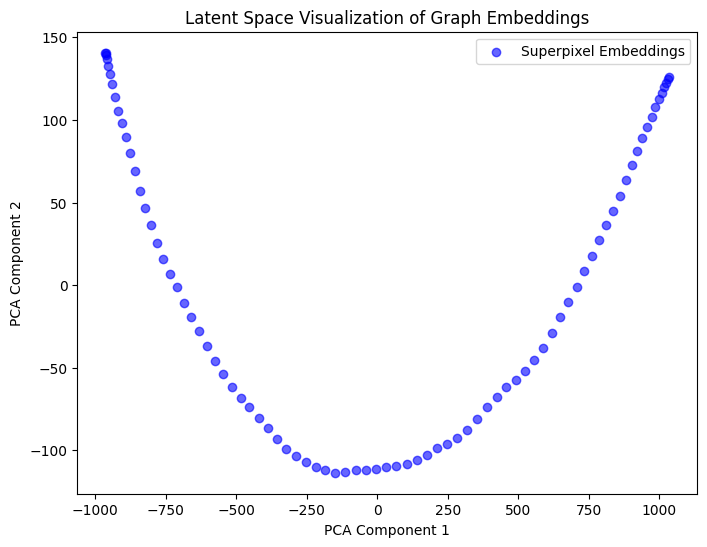

In [25]:
evaluate(model, pyg_data)
visualize_latent_space(model, pyg_data)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


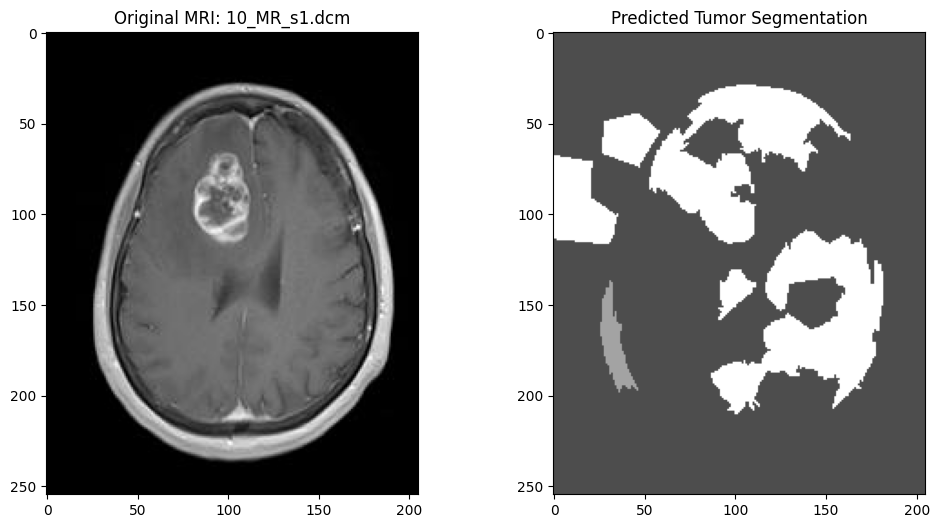

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import torch

def visualize_segmentation(image, segments, predictions, filename):
    """
    Visualizes predicted segmentation overlaid on the MRI image.

    Parameters:
        image (ndarray): The original MRI image.
        segments (ndarray): The superpixel labels.
        predictions (dict): Predicted tumor probabilities for each superpixel.
        filename (str): The filename for reference.
    """
    segmented_image = np.zeros_like(image, dtype=np.float32)

    for segment_id in np.unique(segments):
        mask = segments == segment_id
        segmented_image[mask] = predictions.get(segment_id, 0) * 255  # Scale probability to grayscale

    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(image, cmap='gray')
    ax[0].set_title(f"Original MRI: {filename}")
    
    ax[1].imshow(segmented_image, cmap='hot', alpha=0.7)
    ax[1].set_title("Predicted Tumor Segmentation")

    plt.show()

# Get predicted tumor labels
with torch.no_grad():
    embeddings = model.encoder(pyg_data.x, pyg_data.edge_index, pyg_data.edge_index)
    predictions = model.decoder(embeddings).cpu().numpy().flatten()  # Convert to 1D array

# Map predictions correctly using unique superpixel IDs from `segments_list[0]`
unique_superpixels = np.unique(segments_list[0])  # Get unique superpixel IDs

# Create a dictionary that maps superpixel IDs to their predicted tumor probability
predicted_labels = {segment_id: predictions[i] for i, segment_id in enumerate(unique_superpixels)}

# Visualize segmentation results
visualize_segmentation(images[0], segments_list[0], predicted_labels, filenames[0])



In [27]:
def reconstruct_node_features(model, data):
    """
    Reconstructs original node features using the trained model.

    Parameters:
        model (nn.Module): Trained DGAE model.
        data (PyG Data): Input graph data.

    Returns:
        reconstructed_features (torch.Tensor): Reconstructed node features.
    """
    model.eval()
    with torch.no_grad():
        reconstructed = model(data.x, data.edge_index, data.edge_index)
    return reconstructed

# Reconstruct features for the MRI graph
reconstructed_features = reconstruct_node_features(model, pyg_data)
print("Reconstructed Node Features:\n", reconstructed_features)


Reconstructed Node Features:
 tensor([[-9.7539e-01, -1.6622e+00, -1.4758e+00],
        [-9.8924e-01, -1.5880e+00, -1.2025e+00],
        [-9.2005e-01, -1.4384e+00, -7.3616e-01],
        [-8.7542e-01, -1.3034e+00, -2.7271e-01],
        [-8.4909e-01, -1.3264e+00,  7.0396e-02],
        [-8.3158e-01, -1.3379e+00,  2.9546e-01],
        [-7.6777e-01, -1.3069e+00,  4.1034e-01],
        [-7.1852e-01, -1.1869e+00,  3.9162e-01],
        [-6.6928e-01, -9.6063e-01,  3.1704e-01],
        [-6.2355e-01, -8.3081e-01,  2.7278e-01],
        [-5.6011e-01, -7.4526e-01,  2.7956e-01],
        [-5.0096e-01, -6.8476e-01,  2.9264e-01],
        [-4.6460e-01, -5.5261e-01,  2.3219e-01],
        [-4.8239e-01, -4.9134e-01,  1.2845e-01],
        [-4.8697e-01, -4.5274e-01,  4.4779e-02],
        [-4.4214e-01, -3.9507e-01,  7.1823e-03],
        [-3.9104e-01, -3.7325e-01,  1.9193e-03],
        [-3.3197e-01, -3.6525e-01,  1.1017e-02],
        [-2.5215e-01, -3.4143e-01,  4.3400e-02],
        [-1.9853e-01, -3.0505e-01,  2.2

In [28]:
import pandas as pd

# Convert features to DataFrames for better comparison
original_df = pd.DataFrame(pyg_data.x.cpu().numpy(), columns=['Mean_Intensity', 'Centroid_y', 'Centroid_x'])
reconstructed_df = pd.DataFrame(reconstructed_features.cpu().numpy(), columns=['Reconstructed_Intensity', 'Reconstructed_y', 'Reconstructed_x'])

# Concatenate for side-by-side comparison
comparison_df = pd.concat([original_df, reconstructed_df], axis=1)
comparison_df['Intensity_Diff'] = abs(comparison_df['Mean_Intensity'] - comparison_df['Reconstructed_Intensity'])
comparison_df['Centroid_y_Diff'] = abs(comparison_df['Centroid_y'] - comparison_df['Reconstructed_y'])
comparison_df['Centroid_x_Diff'] = abs(comparison_df['Centroid_x'] - comparison_df['Reconstructed_x'])

# Display the first few rows
print(comparison_df.head(10))


   Mean_Intensity  Centroid_y  Centroid_x  Reconstructed_Intensity  \
0       -0.982655   -1.602089   -1.517149                -0.975386   
1       -0.982655   -1.602089   -1.127704                -0.989241   
2       -0.982655   -1.599187   -0.730698                -0.920054   
3       -0.914781   -1.521042   -0.335387                -0.875416   
4       -0.923209   -1.564219    0.039817                -0.849093   
5       -0.915569   -1.552704    0.421573                -0.831576   
6       -0.949351   -1.503206    0.773181                -0.767772   
7       -0.982655   -1.589154    1.165549                -0.718523   
8       -0.982655   -1.595328    1.567834                -0.669281   
9       -0.982655   -1.281830   -1.521083                -0.623555   

   Reconstructed_y  Reconstructed_x  Intensity_Diff  Centroid_y_Diff  \
0        -1.662167        -1.475756        0.007269         0.060078   
1        -1.588024        -1.202453        0.006586         0.014065   
2        -1.4

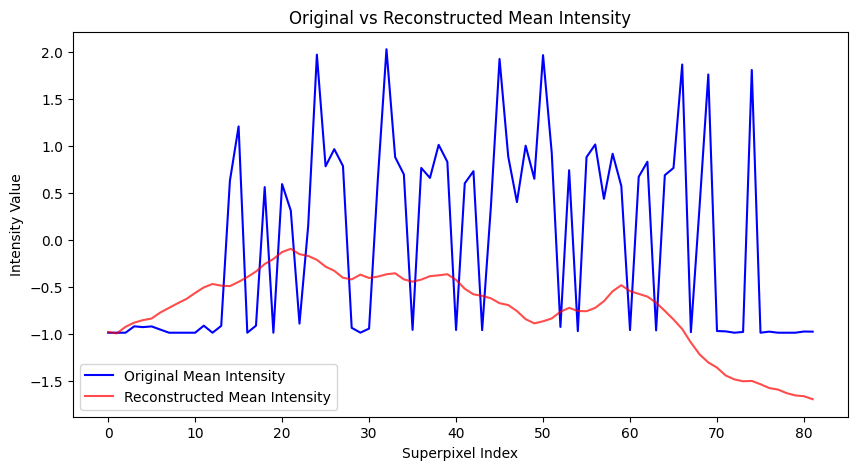

In [29]:
import matplotlib.pyplot as plt

# Plot original vs reconstructed mean intensity
plt.figure(figsize=(10, 5))
plt.plot(comparison_df['Mean_Intensity'], label='Original Mean Intensity', color='blue')
plt.plot(comparison_df['Reconstructed_Intensity'], label='Reconstructed Mean Intensity', color='red', alpha=0.7)
plt.title('Original vs Reconstructed Mean Intensity')
plt.xlabel('Superpixel Index')
plt.ylabel('Intensity Value')
plt.legend()
plt.show()


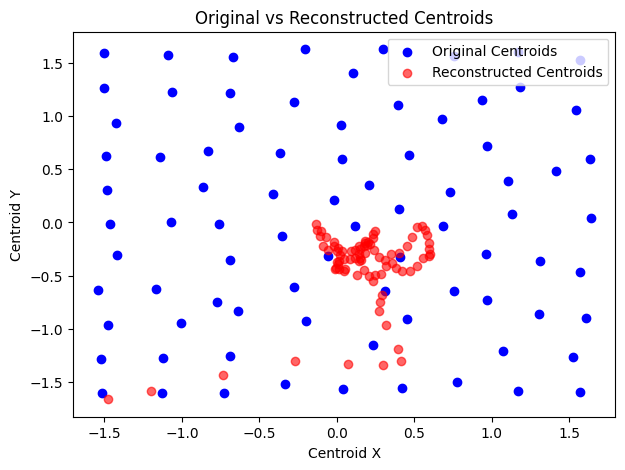

In [30]:
# Scatter plot of original vs reconstructed centroids
plt.figure(figsize=(7, 5))
plt.scatter(comparison_df['Centroid_x'], comparison_df['Centroid_y'], color='blue', label='Original Centroids')
plt.scatter(comparison_df['Reconstructed_x'], comparison_df['Reconstructed_y'], color='red', alpha=0.6, label='Reconstructed Centroids')
plt.title('Original vs Reconstructed Centroids')
plt.xlabel('Centroid X')
plt.ylabel('Centroid Y')
plt.legend()
plt.show()


In [31]:
from sklearn.metrics import mean_squared_error

intensity_mse = mean_squared_error(comparison_df['Mean_Intensity'], comparison_df['Reconstructed_Intensity'])
centroid_x_mse = mean_squared_error(comparison_df['Centroid_x'], comparison_df['Reconstructed_x'])
centroid_y_mse = mean_squared_error(comparison_df['Centroid_y'], comparison_df['Reconstructed_y'])

print(f"Mean Intensity MSE: {intensity_mse:.4f}")
print(f"Centroid X MSE: {centroid_x_mse:.4f}")
print(f"Centroid Y MSE: {centroid_y_mse:.4f}")


Mean Intensity MSE: 1.4773
Centroid X MSE: 1.0156
Centroid Y MSE: 0.9064


In [32]:
import torch
import numpy as np

# Extract node embeddings
model.eval()
with torch.no_grad():
    embeddings = model.encoder(pyg_data.x, pyg_data.edge_index, pyg_data.edge_index)  # Shape: (num_nodes, hidden_dim)

# Convert to numpy for clustering
embeddings_np = embeddings.cpu().numpy()


In [33]:
from sklearn.cluster import KMeans

# Choose number of clusters (e.g., 2 for tumor vs. normal, or 3+ for finer segmentation)
num_clusters = 3
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(embeddings_np)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


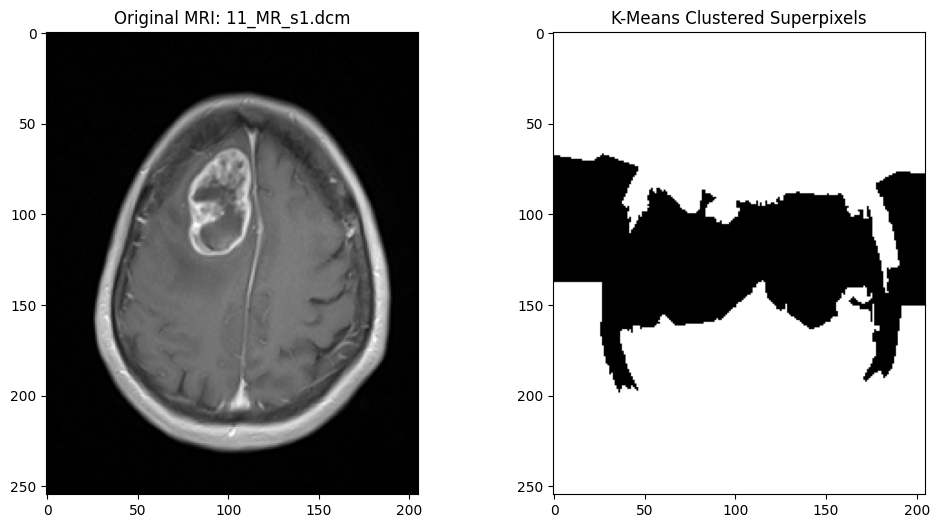

In [34]:
import matplotlib.pyplot as plt

def visualize_clusters(image, segments, cluster_labels, filename):
    """
    Visualizes K-Means clustering results on MRI superpixels.

    Parameters:
        image (ndarray): The original MRI image.
        segments (ndarray): The superpixel labels.
        cluster_labels (ndarray): Cluster assignments for each superpixel.
        filename (str): Image filename.
    """
    clustered_image = np.zeros_like(image, dtype=np.float32)

    for i, segment_id in enumerate(np.unique(segments)):
        mask = segments == segment_id
        clustered_image[mask] = cluster_labels[i]  # Assign cluster label

    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(image, cmap='gray')
    ax[0].set_title(f"Original MRI: {filename}")

    ax[1].imshow(clustered_image, cmap='nipy_spectral')
    ax[1].set_title("K-Means Clustered Superpixels")

    plt.show()

# Visualize clustering results
visualize_clusters(images[1], segments_list[0], cluster_labels, filenames[5])


In [35]:
import collections

# Count superpixels per cluster
cluster_counts = collections.Counter(cluster_labels)
print("Cluster Distribution:", cluster_counts)


Cluster Distribution: Counter({1: 31, 2: 28, 0: 23})


In [36]:
torch.save(model.state_dict(), "tumorgraphnet_model.pt")